# DCIT 316 Final Project - Misinformation Detection
## EDA and Baseline Model
Dataset: Fake and Real News Dataset (ISOT), Kaggle

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option('display.max_colwidth', 100)

print("Current working directory:", os.getcwd())

Current working directory: C:\Users\jessy\OneDrive - University of Ghana\Documents\L300 SEM2\DCIT316\Sem-Project\zunuo_dcit316-final-project


In [7]:
fake = pd.read_csv('data/raw/Fake.csv')
true = pd.read_csv('data/raw/True.csv')

fake['label'] = 'fake'
true['label'] = 'real'

df = pd.concat([fake, true], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

print(df.shape)
df.head()

(44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution,"21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some ...",US_News,"February 13, 2017",fake
1,Trump drops Steve Bannon from National Security Council,WASHINGTON (Reuters) - U.S. President Donald Trump removed his chief strategist Steve Bannon fro...,politicsNews,"April 5, 2017",real
2,Puerto Rico expects U.S. to lift Jones Act shipping restrictions,(Reuters) - Puerto Rico Governor Ricardo Rossello said on Wednesday he expected the federal gove...,politicsNews,"September 27, 2017",real
3,OOPS: Trump Just Accidentally Confirmed He Leaked Israeli Intelligence To Russia (VIDEO),"On Monday, Donald Trump once again embarrassed himself and his country by accidentally revealing...",News,"May 22, 2017",fake
4,Donald Trump heads for Scotland to reopen a golf resort,"GLASGOW, Scotland (Reuters) - Most U.S. presidential candidates go abroad to sharpen their forei...",politicsNews,"June 24, 2016",real


label
fake    23481
real    21417
Name: count, dtype: int64


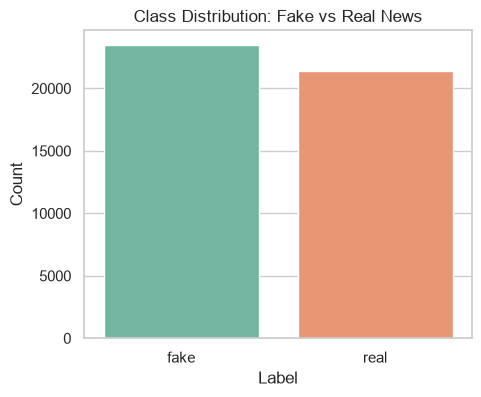

In [9]:
class_counts = df['label'].value_counts()
print(class_counts)

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='label', hue='label', palette='Set2', legend=False)
plt.title('Class Distribution: Fake vs Real News')
plt.xlabel('Label')
plt.ylabel('Count')
plt.savefig('reports/figures/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

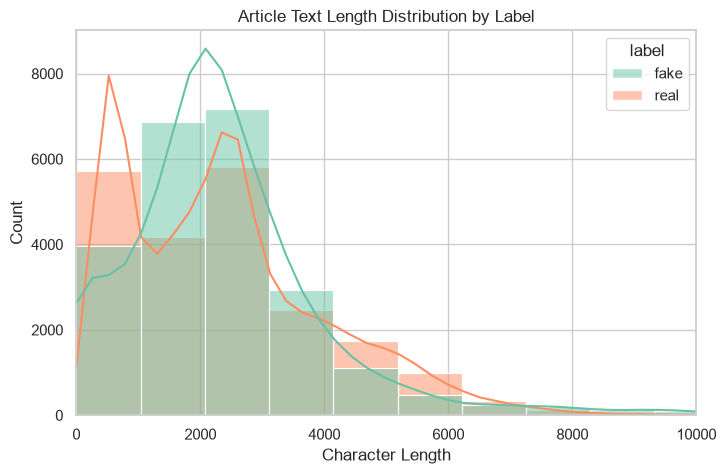

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
fake,23481.0,2547.396235,2532.884399,1.0,1433.0,2166.0,3032.0,51794.0
real,21417.0,2383.278517,1684.835730,1.0,914.0,2222.0,3237.0,29781.0


In [10]:
df['text_length'] = df['text'].astype(str).apply(len)

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='text_length', hue='label', bins=50, kde=True, palette='Set2')
plt.title('Article Text Length Distribution by Label')
plt.xlabel('Character Length')
plt.xlim(0, 10000)
plt.savefig('reports/figures/text_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

df.groupby('label')['text_length'].describe()

subject
politicsNews       11272
worldnews          10145
News                9050
politics            6841
left-news           4459
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64


<function matplotlib.pyplot.title(label: 'str', fontdict: 'dict[str, Any] | None' = None, loc: "Literal['left', 'center', 'right'] | None" = None, pad: 'float | None' = None, *, y: 'float | None' = None, **kwargs) -> 'Text'>

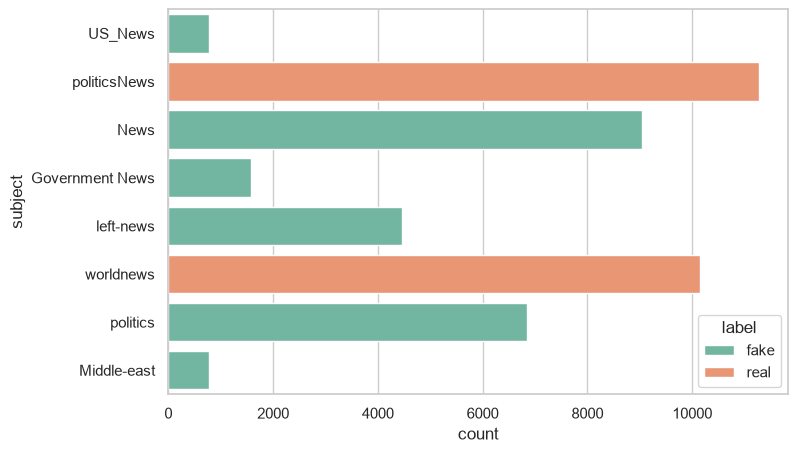

In [11]:
print(df['subject'].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, y='subject', hue='label', palette='Set2')
plt.title